# Project 1 – Natural Language Inference (SNLI)

**Task:** given a *premise* and a *hypothesis*, predict whether the premise **entails**, **contradicts** or is **neutral** towards the hypothesis.

**What we compare:**

| | |
|---|---|
| **Representations** | R1 token indicators · R2 bag-of-words · R3 bag-of-words + cross-sentence features |
| **Architectures** | A1 log-linear · A2 MLP (tutorial) · A3 MLP with more regularisation |
| **Evaluation** | 5-fold cross-validation, accuracy, Bayesian estimation with a ROPE |


## 0. Setup

In [1]:
import re
import sys
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

warnings.simplefilter("ignore")

# the course code (part1/) is in the same folder as this notebook
sys.path.insert(0, ".")
import part1

# the three labels, in the same order as SNLI uses them (0, 1, 2)
LABELS = part1.clslib.NamedClasses(["entailment", "neutral", "contradiction"])

SEED = 0

## 1. Data

We use SNLI. Pairs with label −1 are removed: those are pairs where the annotators did not agree on a label.

To keep the experiments fast we take a random **sample of 20,000 training pairs**. Every example is stored as `((premise, hypothesis), label)`.
- `train_pairs`: used for the tokenizer and cross-validation
- `val_pairs`: 2,000 pairs from SNLI's validation split, only used to look at how the MLP trains (section 6)
- `test_pairs`: SNLI's test split, used **once** at the very end

In [2]:
snli = load_dataset("stanfordnlp/snli")
print(snli)


def to_pairs(split):
    # turn a SNLI split into a list of ((premise, hypothesis), label)
    pairs = []
    for premise, hypothesis, label in zip(split["premise"], split["hypothesis"], split["label"]):
        if label != -1:   # -1 means the annotators did not agree, so we skip it
            pairs.append(((premise, hypothesis), label))
    return pairs


all_train = to_pairs(snli["train"])
all_val = to_pairs(snli["validation"])
test_pairs = to_pairs(snli["test"])

# take a random sample (with the same seed we get the same sample every time)
rng = np.random.default_rng(SEED)

train_order = rng.permutation(len(all_train))
train_pairs = []
for i in train_order[:20000]:
    train_pairs.append(all_train[i])

val_order = rng.permutation(len(all_val))
val_pairs = []
for i in val_order[:2000]:
    val_pairs.append(all_val[i])

print("train:", len(train_pairs), "| val:", len(val_pairs), "| test:", len(test_pairs))

removed = 0
for label in snli["train"]["label"]:
    if label == -1:
        removed += 1
print("removed (label -1) in the full train split:", removed)

print("example:", train_pairs[0])

DatasetDict({
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 550152
    })
})
train: 20000 | val: 2000 | test: 9824
removed (label -1) in the full train split: 785
example: (('A man holding a video camera standing next to a woman by water.', 'The man is holding a microphone as he introduces the woman standing by the water.'), 2)


To find out whether we can use **accuracy** as an evaluation metric, we have to check whether the classes are balanced. If one class were much bigger, a model could get a high accuracy by mostly predicting that class.

entailment 6571 -> 0.329
neutral 6630 -> 0.332
contradiction 6799 -> 0.34


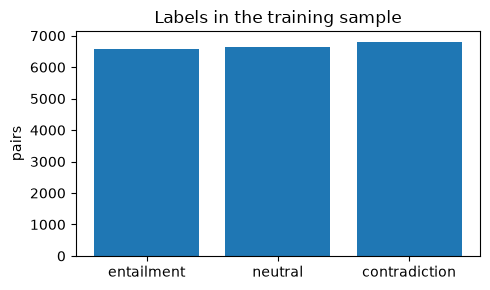

majority baseline: 0.34


In [3]:
label_counts = Counter()
for pair, label in train_pairs:
    label_counts[LABELS.name(label)] += 1

for name in LABELS:
    print(name, label_counts[name], "->", round(label_counts[name] / len(train_pairs), 3))

plt.figure(figsize=(5, 3))
plt.bar(list(LABELS), [label_counts[name] for name in LABELS])
plt.title("Labels in the training sample")
plt.ylabel("pairs")
plt.tight_layout()
plt.show()

# majority baseline: the accuracy you get by always predicting the biggest class
majority = max(label_counts.values()) / len(train_pairs)
print("majority baseline:", round(majority, 3))

Some quick statistics that motivate the features in R3 (section 5): how long are premises and hypotheses, and how often does the hypothesis contain a negation, per label?

In [4]:
# a regular expression that finds negation words like "not", "no", "nobody", "isn't"
NEGATION = re.compile(r"\b(?:not|no|never|nobody|nothing|none|cannot)\b|n't", re.IGNORECASE)


def has_negation(sentence):
    if NEGATION.search(sentence):
        return True
    else:
        return False


rows = []
for (premise, hypothesis), label in train_pairs:
    rows.append({
        "label": LABELS.name(label),
        "premise words": len(premise.split()),
        "hypothesis words": len(hypothesis.split()),
        "negation in hypothesis": has_negation(hypothesis),
    })
stats = pd.DataFrame(rows)

# average per label
stats.groupby("label").mean().loc[list(LABELS)].round(3)

,premise words,hypothesis words,negation in hypothesis
label,,,
entailment,12.944,6.669,0.007
neutral,12.802,8.195,0.009
contradiction,12.869,7.313,0.049


## 2. Tokenizer

As in the tutorial: a BPE tokenizer with `vocab_size=1000` and `min_frequency=2`, trained with the course's `train_tokenizer`. We train it on the premises and hypotheses of the **training pairs only**, so it never sees the test data.

In [5]:
corpus = []
for (premise, hypothesis), label in train_pairs:
    corpus.append(premise)
for (premise, hypothesis), label in train_pairs:
    corpus.append(hypothesis)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size=1000, min_frequency=2)

# look at one example
premise = train_pairs[0][0][0]
hypothesis = train_pairs[0][0][1]
print("premise:   ", tokenizer.encode(premise).tokens)
print("hypothesis:", tokenizer.encode(hypothesis).tokens)




premise:    ['▁A', '▁man', '▁holding', '▁a', '▁v', 'ide', 'o', '▁camera', '▁standing', '▁next', '▁to', '▁a', '▁woman', '▁by', '▁water.']
hypothesis: ['▁The', '▁man', '▁is', '▁holding', '▁a', '▁micro', 'phone', '▁as', '▁he', '▁in', 't', 'ro', 'd', 'u', 'c', 'es', '▁the', '▁woman', '▁standing', '▁by', '▁the', '▁water.']


## 3. Representations R1 and R2

The tutorial's encoders turn **one** text into a vector. NLI has **two** texts, and it matters which sentence a word is in ("not" in the hypothesis means something different from "not" in the premise). So we make a vector for the premise and a vector for the hypothesis **separately** and put them next to each other:

`[ premise vector (V numbers) | hypothesis vector (V numbers) ]` → 2V numbers, with V = 1000.

- **R1 – token indicators:** 1 if a token is in the sentence, 0 if not.
- **R2 – bag-of-words:** how many times each token is in the sentence.

The only difference in the code is `= 1` (R1) versus `+= 1` (R2).

In [6]:
class PairIndicator:
    # R1: for premise and hypothesis, 1 if a token is in the sentence, 0 if not

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] = 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] = 1

        # put them next to each other
        return np.concatenate([premise_vector, hypothesis_vector])


class PairBagOfWords:
    # R2: same as R1 but we count how many times each token occurs

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        return self.vocab_size * 2

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        return np.concatenate([premise_vector, hypothesis_vector])

In [7]:
R1 = PairIndicator(tokenizer)
R2 = PairBagOfWords(tokenizer)

# test on an example
x = ("A man is playing a guitar on a stage.", "A man is not playing music.")
print("dimensions:", len(R1), len(R2))
print("sum of R1:", R1(x).sum(), "| sum of R2:", R2(x).sum())   # R2 is bigger because "a" is counted twice

dimensions: 2000 2000
sum of R1: 16.0 | sum of R2: 17.0


## 4. Cross-validation with A1 and A2

We use the course's `cross_validation_split` (5 folds) and `cross_validation_experiment`. The architectures are just settings for that function:

- **A1** – log-linear softmax regression (scikit-learn), as in the tutorial
- **A2** – one-hidden-layer MLP with the tutorial's settings

`run(name, encoder, architecture)` does the cross-validation for one system and stores the results in `my_classifiers`, in the same format as the tutorial, so the course's analysis functions work on it.

`my_seeds = [0]` gives 5 accuracies per system (one per fold).

In [8]:
A1 = {
    "model_option": "logistic",
    "loglin_args": {"max_iter": 100},
    "smlp_args": {},
}

A2 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 128, "dropout": 0.1, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 10},
}

num_folds = 5
my_seeds = [0]

# make the folds once, so every system uses exactly the same folds
cv_sets = {}
for seed in my_seeds:
    cv_sets[seed] = part1.experiment.cross_validation_split(train_pairs, k=num_folds, seed=seed)

my_classifiers = {}


def run(name, encoder, architecture):
    # cross-validate one system and save the results under `name`
    my_classifiers[name] = []
    all_accuracies = []

    for seed in my_seeds:
        result = part1.experiment.cross_validation_experiment(
            data_splits=cv_sets[seed],
            outcome_space=LABELS,
            encoder=encoder,
            model_option=architecture["model_option"],
            loglin_args=architecture["loglin_args"],
            smlp_args=architecture["smlp_args"],
            save_to="results/" + name + "/seed-" + str(seed),
        )
        my_classifiers[name].append(result)

        for accuracy in result["accuracies"].values():
            all_accuracies.append(accuracy)

    print(name, "mean accuracy:", round(np.mean(all_accuracies), 4), "(std", round(np.std(all_accuracies), 4), ")")

In [9]:
run("A1_R1", R1, A1)
run("A1_R2", R2, A1)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R1 mean accuracy: 0.552 (std 0.0027 )


  0%|          | 0/5 [00:00<?, ?it/s]

A1_R2 mean accuracy: 0.5503 (std 0.0024 )


In [10]:
run("A2_R1", R1, A2)
run("A2_R2", R2, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.766 seconds
Dataloader done! Time taken: 0.215 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0918 | train acc: 0.3885 | val loss: 1.0802 | val acc: 0.4330
Epoch 02 | train loss: 1.0605 | train acc: 0.5021 | val loss: 1.0496 | val acc: 0.5040
Epoch 03 | train loss: 1.0165 | train acc: 0.5572 | val loss: 1.0127 | val acc: 0.5312
Epoch 04 | train loss: 0.9673 | train acc: 0.5807 | val loss: 0.9811 | val acc: 0.5395
Epoch 05 | train loss: 0.9268 | train acc: 0.5964 | val loss: 0.9614 | val acc: 0.5520
Epoch 06 | train loss: 0.8917 | train acc: 0.6133 | val loss: 0.9487 | val acc: 0.5617
Epoch 07 | train loss: 0.8633 | train acc: 0.6271 | val loss: 0.9426 | val acc: 0.5600
Epoch 08 | train loss: 0.8398 | train acc: 0.6410 | val loss: 0.9369 | val acc: 0.5653
Epoch 09 | train loss: 0.8187 | train acc: 0.6496 | val loss: 0.9352 | val acc: 0.5645
Epoch 10 | train loss: 0.8008 | train acc: 0.6594 | val loss: 0.9349 | val acc: 0.5630
Training done! Time taken: 10.404 seconds
Transforming documents...
Document transformation done! Time taken: 0.812 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0897 | train acc: 0.3844 | val loss: 1.0788 | val acc: 0.4522
Epoch 02 | train loss: 1.0562 | train acc: 0.5137 | val loss: 1.0469 | val acc: 0.5092
Epoch 03 | train loss: 1.0094 | train acc: 0.5549 | val loss: 1.0095 | val acc: 0.5270
Epoch 04 | train loss: 0.9609 | train acc: 0.5807 | val loss: 0.9809 | val acc: 0.5400
Epoch 05 | train loss: 0.9211 | train acc: 0.5992 | val loss: 0.9622 | val acc: 0.5485
Epoch 06 | train loss: 0.8873 | train acc: 0.6138 | val loss: 0.9492 | val acc: 0.5537
Epoch 07 | train loss: 0.8604 | train acc: 0.6283 | val loss: 0.9418 | val acc: 0.5583
Epoch 08 | train loss: 0.8371 | train acc: 0.6381 | val loss: 0.9363 | val acc: 0.5575
Epoch 09 | train loss: 0.8171 | train acc: 0.6521 | val loss: 0.9335 | val acc: 0.5593
Epoch 10 | train loss: 0.7981 | train acc: 0.6646 | val loss: 0.9319 | val acc: 0.5613
Training done! Time taken: 9.144 seconds
Transforming documents...
Document transformation done! Time taken: 0.825 seconds
Dataloa

... (14 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0899 | train acc: 0.3852 | val loss: 1.0786 | val acc: 0.4462
Epoch 02 | train loss: 1.0553 | train acc: 0.5074 | val loss: 1.0491 | val acc: 0.4998
Epoch 03 | train loss: 1.0108 | train acc: 0.5573 | val loss: 1.0163 | val acc: 0.5138
Epoch 04 | train loss: 0.9634 | train acc: 0.5834 | val loss: 0.9904 | val acc: 0.5280
Epoch 05 | train loss: 0.9236 | train acc: 0.5989 | val loss: 0.9719 | val acc: 0.5410
Epoch 06 | train loss: 0.8904 | train acc: 0.6157 | val loss: 0.9598 | val acc: 0.5455
Epoch 07 | train loss: 0.8631 | train acc: 0.6274 | val loss: 0.9508 | val acc: 0.5527
Epoch 08 | train loss: 0.8397 | train acc: 0.6425 | val loss: 0.9470 | val acc: 0.5520
Epoch 09 | train loss: 0.8191 | train acc: 0.6510 | val loss: 0.9435 | val acc: 0.5557
Epoch 10 | train loss: 0.8003 | train acc: 0.6599 | val loss: 0.9424 | val acc: 0.5595
Training done! Time taken: 8.957 seconds
Transforming documents...
Document transformation done! Time taken: 0.843 seconds
Dataloa

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0916 | train acc: 0.3816 | val loss: 1.0821 | val acc: 0.4230
Epoch 02 | train loss: 1.0612 | train acc: 0.5028 | val loss: 1.0536 | val acc: 0.4973
Epoch 03 | train loss: 1.0165 | train acc: 0.5519 | val loss: 1.0182 | val acc: 0.5168
Epoch 04 | train loss: 0.9683 | train acc: 0.5802 | val loss: 0.9900 | val acc: 0.5272
Epoch 05 | train loss: 0.9265 | train acc: 0.6009 | val loss: 0.9717 | val acc: 0.5353
Epoch 06 | train loss: 0.8924 | train acc: 0.6126 | val loss: 0.9594 | val acc: 0.5410
Epoch 07 | train loss: 0.8637 | train acc: 0.6256 | val loss: 0.9528 | val acc: 0.5407
Epoch 08 | train loss: 0.8395 | train acc: 0.6388 | val loss: 0.9481 | val acc: 0.5477
Epoch 09 | train loss: 0.8197 | train acc: 0.6500 | val loss: 0.9461 | val acc: 0.5457
Epoch 10 | train loss: 0.8009 | train acc: 0.6587 | val loss: 0.9452 | val acc: 0.5470
Training done! Time taken: 8.979 seconds
A2_R2 mean accuracy: 0.5551 (std 0.0049 )


## 5. Representation R3: cross-sentence features

R1 and R2 describe each sentence on its own. But NLI is about **how the two sentences relate**, and a log-linear model cannot work that out from two separate halves of a vector. R3 adds features that describe the relation directly:

| Feature | Idea |
|---|---|
| **new tokens in H** (V numbers) | tokens in the hypothesis that are not in the premise → new information suggests *neutral* |
| **overlap** | share of hypothesis tokens that also occur in the premise → high overlap suggests *entailment* |
| **length difference** | (len H − len P) / (len H + len P) |
| **negation** | hypothesis has a negation word and the premise does not → suggests *contradiction* |

R3 = R2 + these features → 3V + 3 numbers. All extra features are between −1 and 1, on the same scale as the other features.

In [11]:
class PairCrossFeatures:
    # R3: R2 + features that compare the premise and the hypothesis

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()

    def __len__(self):
        # premise part + hypothesis part + new-tokens part + 3 extra numbers
        return self.vocab_size * 3 + 3

    def __call__(self, x):
        premise = x[0]
        hypothesis = x[1]

        premise_ids = self.tokenizer.encode(premise).ids
        hypothesis_ids = self.tokenizer.encode(hypothesis).ids

        # part 1 and 2: bag-of-words, the same as R2
        premise_vector = np.zeros(self.vocab_size)
        for i in premise_ids:
            premise_vector[i] += 1

        hypothesis_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            hypothesis_vector[i] += 1

        # part 3: tokens that are in the hypothesis but NOT in the premise
        new_vector = np.zeros(self.vocab_size)
        for i in hypothesis_ids:
            if i not in premise_ids:
                new_vector[i] = 1

        # overlap: which part of the hypothesis tokens also appears in the premise
        if len(hypothesis_ids) > 0:
            in_premise = 0
            for i in hypothesis_ids:
                if i in premise_ids:
                    in_premise += 1
            overlap = in_premise / len(hypothesis_ids)
        else:
            overlap = 0

        # length difference, scaled to be between -1 and 1
        total_length = len(hypothesis_ids) + len(premise_ids)
        if total_length > 0:
            length_difference = (len(hypothesis_ids) - len(premise_ids)) / total_length
        else:
            length_difference = 0

        # negation: 1 if the hypothesis has a negation word and the premise doesn't
        if has_negation(hypothesis) and not has_negation(premise):
            negation = 1
        else:
            negation = 0

        extra = np.array([overlap, length_difference, negation])
        return np.concatenate([premise_vector, hypothesis_vector, new_vector, extra])


R3 = PairCrossFeatures(tokenizer)
print("dimensions:", len(R3))
print("overlap, length difference, negation for the example:", R3(x)[-3:])

dimensions: 3003
overlap, length difference, negation for the example: [ 0.57142857 -0.17647059  1.        ]


In [12]:
run("A1_R3", R3, A1)
run("A2_R3", R3, A2)

  0%|          | 0/5 [00:00<?, ?it/s]

A1_R3 mean accuracy: 0.6257 (std 0.0046 )


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.023 seconds
Dataloader done! Time taken: 0.304 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0745 | train acc: 0.4567 | val loss: 1.0445 | val acc: 0.5235
Epoch 02 | train loss: 0.9964 | train acc: 0.5808 | val loss: 0.9637 | val acc: 0.5877
Epoch 03 | train loss: 0.9080 | train acc: 0.6248 | val loss: 0.9026 | val acc: 0.6105
Epoch 04 | train loss: 0.8383 | train acc: 0.6554 | val loss: 0.8644 | val acc: 0.6252
Epoch 05 | train loss: 0.7883 | train acc: 0.6699 | val loss: 0.8431 | val acc: 0.6312
Epoch 06 | train loss: 0.7496 | train acc: 0.6899 | val loss: 0.8317 | val acc: 0.6328
Epoch 07 | train loss: 0.7218 | train acc: 0.7016 | val loss: 0.8261 | val acc: 0.6338
Epoch 08 | train loss: 0.6971 | train acc: 0.7138 | val loss: 0.8219 | val acc: 0.6340
Epoch 09 | train loss: 0.6775 | train acc: 0.7220 | val loss: 0.8195 | val acc: 0.6345
Epoch 10 | train loss: 0.6602 | train acc: 0.7299 | val loss: 0.8215 | val acc: 0.6330
Training done! Time taken: 10.221 seconds
Transforming documents...
Document transformation done! Time taken: 0.966 seconds
Datalo

... (4 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0776 | train acc: 0.4522 | val loss: 1.0486 | val acc: 0.5495
Epoch 02 | train loss: 0.9943 | train acc: 0.5910 | val loss: 0.9688 | val acc: 0.5833
Epoch 03 | train loss: 0.9032 | train acc: 0.6266 | val loss: 0.9079 | val acc: 0.6025
Epoch 04 | train loss: 0.8342 | train acc: 0.6561 | val loss: 0.8709 | val acc: 0.6140
Epoch 05 | train loss: 0.7855 | train acc: 0.6743 | val loss: 0.8487 | val acc: 0.6220
Epoch 06 | train loss: 0.7490 | train acc: 0.6901 | val loss: 0.8374 | val acc: 0.6242
Epoch 07 | train loss: 0.7198 | train acc: 0.7049 | val loss: 0.8296 | val acc: 0.6280
Epoch 08 | train loss: 0.6970 | train acc: 0.7124 | val loss: 0.8256 | val acc: 0.6285
Epoch 09 | train loss: 0.6764 | train acc: 0.7205 | val loss: 0.8257 | val acc: 0.6280
Epoch 10 | train loss: 0.6590 | train acc: 0.7288 | val loss: 0.8245 | val acc: 0.6290
Training done! Time taken: 10.912 seconds
Transforming documents...
Document transformation done! Time taken: 1.119 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0781 | train acc: 0.4449 | val loss: 1.0502 | val acc: 0.5460
Epoch 02 | train loss: 0.9972 | train acc: 0.5972 | val loss: 0.9678 | val acc: 0.5825
Epoch 03 | train loss: 0.9027 | train acc: 0.6353 | val loss: 0.9067 | val acc: 0.5990
Epoch 04 | train loss: 0.8311 | train acc: 0.6594 | val loss: 0.8714 | val acc: 0.6068
Epoch 05 | train loss: 0.7814 | train acc: 0.6781 | val loss: 0.8524 | val acc: 0.6208
Epoch 06 | train loss: 0.7466 | train acc: 0.6917 | val loss: 0.8405 | val acc: 0.6282
Epoch 07 | train loss: 0.7165 | train acc: 0.7059 | val loss: 0.8359 | val acc: 0.6350
Epoch 08 | train loss: 0.6935 | train acc: 0.7155 | val loss: 0.8314 | val acc: 0.6350
Epoch 09 | train loss: 0.6735 | train acc: 0.7212 | val loss: 0.8312 | val acc: 0.6342
Epoch 10 | train loss: 0.6558 | train acc: 0.7299 | val loss: 0.8317 | val acc: 0.6378
Training done! Time taken: 10.882 seconds
A2_R3 mean accuracy: 0.6358 (std 0.0044 )


## 6. Architecture A3: a more regularised MLP

To choose a sensible change to the MLP, we first look at **how A2 trains**: we train it once on the training pairs and look at the accuracy on the separate `val_pairs` after every epoch.

- If training accuracy keeps going up while validation accuracy stops improving, the model is **overfitting** (it memorises the training data). Then we need more regularisation.
- If both stay low, the model is **underfitting**. Then we need a bigger model.

Transforming documents...
Document transformation done! Time taken: 1.112 seconds
Dataloader done! Time taken: 0.279 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0881 | train acc: 0.3956 | val loss: 1.0738 | val acc: 0.4490
Epoch 02 | train loss: 1.0470 | train acc: 0.5150 | val loss: 1.0292 | val acc: 0.5045
Epoch 03 | train loss: 0.9948 | train acc: 0.5589 | val loss: 0.9854 | val acc: 0.5350
Epoch 04 | train loss: 0.9455 | train acc: 0.5826 | val loss: 0.9543 | val acc: 0.5490
Epoch 05 | train loss: 0.9071 | train acc: 0.6018 | val loss: 0.9355 | val acc: 0.5560
Epoch 06 | train loss: 0.8770 | train acc: 0.6170 | val loss: 0.9251 | val acc: 0.5630
Epoch 07 | train loss: 0.8527 | train acc: 0.6293 | val loss: 0.9189 | val acc: 0.5665
Epoch 08 | train loss: 0.8313 | train acc: 0.6423 | val loss: 0.9166 | val acc: 0.5710
Epoch 09 | train loss: 0.8149 | train acc: 0.6488 | val loss: 0.9142 | val acc: 0.5720
Epoch 10 | train loss: 0.7986 | train acc: 0.6558 | val loss: 0.9157 | val acc: 0.5655
Training done! Time taken: 10.505 seconds


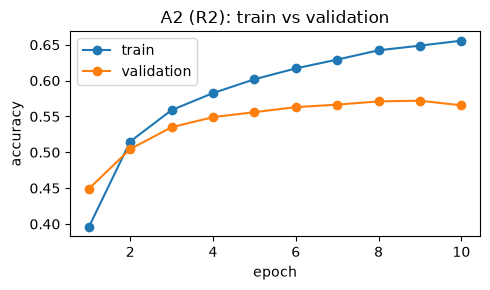

gap at the last epoch: 0.09


In [13]:
def training_curve(architecture):
    # train once on train_pairs (with R2) and return train and validation accuracy per epoch
    settings = architecture["smlp_args"]
    metrics, best_epoch, predictions = part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), R2, save_to="results/curve",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    train_accuracy = []
    val_accuracy = []
    for epoch in metrics:
        train_accuracy.append(epoch["train_metrics"]["accuracy"])
        val_accuracy.append(epoch["val_metrics"]["accuracy"])
    return train_accuracy, val_accuracy


train_acc, val_acc = training_curve(A2)

epochs = range(1, len(train_acc) + 1)
plt.figure(figsize=(5, 3))
plt.plot(epochs, train_acc, marker="o", label="train")
plt.plot(epochs, val_acc, marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("A2 (R2): train vs validation")
plt.legend()
plt.tight_layout()
plt.show()

print("gap at the last epoch:", round(train_acc[-1] - val_acc[-1], 3))

**A3** follows from what we see: A2's validation accuracy levels off while training accuracy keeps going up, so A2 overfits. With only 20k pairs and 2,000+ input numbers, the network has many more weights than there are examples.

A3 therefore uses a **smaller hidden layer (32 instead of 128)** and **stronger dropout (0.5 instead of 0.1)**. Because this makes learning slower, it trains for **30 epochs** instead of 10. The course code keeps the epoch with the best validation loss, so extra epochs cannot hurt.

In [14]:
A3 = {
    "model_option": "mlp",
    "loglin_args": {},
    "smlp_args": {"hidden_dim": 32, "dropout": 0.5, "batch_size": 64,
                  "learning_rate": 1e-4, "weight_decay": 1e-4, "num_epochs": 30},
}

train_acc3, val_acc3 = training_curve(A3)
print("A3 last epoch: train", round(train_acc3[-1], 3), "| validation", round(val_acc3[-1], 3),
      "| gap", round(train_acc3[-1] - val_acc3[-1], 3))

Transforming documents...
Document transformation done! Time taken: 0.983 seconds
Dataloader done! Time taken: 0.306 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1085 | train acc: 0.3444 | val loss: 1.0953 | val acc: 0.3720
Epoch 02 | train loss: 1.0876 | train acc: 0.3864 | val loss: 1.0821 | val acc: 0.4275
Epoch 03 | train loss: 1.0712 | train acc: 0.4289 | val loss: 1.0675 | val acc: 0.4635
Epoch 04 | train loss: 1.0536 | train acc: 0.4750 | val loss: 1.0489 | val acc: 0.4935
Epoch 05 | train loss: 1.0305 | train acc: 0.4984 | val loss: 1.0269 | val acc: 0.5115
Epoch 06 | train loss: 1.0114 | train acc: 0.5183 | val loss: 1.0092 | val acc: 0.5265
Epoch 07 | train loss: 0.9931 | train acc: 0.5310 | val loss: 0.9925 | val acc: 0.5320
Epoch 08 | train loss: 0.9735 | train acc: 0.5433 | val loss: 0.9799 | val acc: 0.5390
Epoch 09 | train loss: 0.9602 | train acc: 0.5582 | val loss: 0.9682 | val acc: 0.5475
Epoch 10 | train loss: 0.9476 | train acc: 0.5655 | val loss: 0.9599 | val acc: 0.5540
Epoch 11 | train loss: 0.9335 | train acc: 0.5700 | val loss: 0.9529 | val acc: 0.5530
Epoch 12 | train loss: 0.9242 | train acc: 

In [15]:
run("A3_R1", R1, A3)
run("A3_R2", R2, A3)
run("A3_R3", R3, A3)

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.913 seconds
Dataloader done! Time taken: 0.215 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1044 | train acc: 0.3355 | val loss: 1.0966 | val acc: 0.3703
Epoch 02 | train loss: 1.0919 | train acc: 0.3836 | val loss: 1.0878 | val acc: 0.4188
Epoch 03 | train loss: 1.0793 | train acc: 0.4249 | val loss: 1.0766 | val acc: 0.4703
Epoch 04 | train loss: 1.0643 | train acc: 0.4579 | val loss: 1.0619 | val acc: 0.4848
Epoch 05 | train loss: 1.0458 | train acc: 0.4900 | val loss: 1.0451 | val acc: 0.5135
Epoch 06 | train loss: 1.0263 | train acc: 0.5089 | val loss: 1.0281 | val acc: 0.5325
Epoch 07 | train loss: 1.0093 | train acc: 0.5258 | val loss: 1.0137 | val acc: 0.5403
Epoch 08 | train loss: 0.9936 | train acc: 0.5310 | val loss: 1.0012 | val acc: 0.5467
Epoch 09 | train loss: 0.9741 | train acc: 0.5523 | val loss: 0.9893 | val acc: 0.5483
Epoch 10 | train loss: 0.9616 | train acc: 0.5583 | val loss: 0.9799 | val acc: 0.5503
Epoch 11 | train loss: 0.9465 | train acc: 0.5681 | val loss: 0.9718 | val acc: 0.5517
Epoch 12 | train loss: 0.9351 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0991 | train acc: 0.3472 | val loss: 1.0928 | val acc: 0.3847
Epoch 02 | train loss: 1.0894 | train acc: 0.3861 | val loss: 1.0844 | val acc: 0.4358
Epoch 03 | train loss: 1.0773 | train acc: 0.4301 | val loss: 1.0730 | val acc: 0.4662
Epoch 04 | train loss: 1.0599 | train acc: 0.4698 | val loss: 1.0576 | val acc: 0.5010
Epoch 05 | train loss: 1.0421 | train acc: 0.4936 | val loss: 1.0405 | val acc: 0.5135
Epoch 06 | train loss: 1.0243 | train acc: 0.5033 | val loss: 1.0250 | val acc: 0.5220
Epoch 07 | train loss: 1.0041 | train acc: 0.5252 | val loss: 1.0105 | val acc: 0.5260
Epoch 08 | train loss: 0.9885 | train acc: 0.5351 | val loss: 0.9987 | val acc: 0.5325
Epoch 09 | train loss: 0.9741 | train acc: 0.5466 | val loss: 0.9884 | val acc: 0.5320
Epoch 10 | train loss: 0.9588 | train acc: 0.5564 | val loss: 0.9796 | val acc: 0.5350
Epoch 11 | train loss: 0.9471 | train acc: 0.5640 | val loss: 0.9720 | val acc: 0.5430
Epoch 12 | train loss: 0.9346 | train acc: 

... (26 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0945 | train acc: 0.3701 | val loss: 1.0825 | val acc: 0.4400
Epoch 02 | train loss: 1.0660 | train acc: 0.4539 | val loss: 1.0532 | val acc: 0.5208
Epoch 03 | train loss: 1.0291 | train acc: 0.5159 | val loss: 1.0154 | val acc: 0.5607
Epoch 04 | train loss: 0.9863 | train acc: 0.5573 | val loss: 0.9796 | val acc: 0.5713
Epoch 05 | train loss: 0.9524 | train acc: 0.5754 | val loss: 0.9511 | val acc: 0.5880
Epoch 06 | train loss: 0.9220 | train acc: 0.5962 | val loss: 0.9275 | val acc: 0.5942
Epoch 07 | train loss: 0.8980 | train acc: 0.6058 | val loss: 0.9092 | val acc: 0.6018
Epoch 08 | train loss: 0.8742 | train acc: 0.6250 | val loss: 0.8944 | val acc: 0.6068
Epoch 09 | train loss: 0.8563 | train acc: 0.6324 | val loss: 0.8807 | val acc: 0.6120
Epoch 10 | train loss: 0.8393 | train acc: 0.6436 | val loss: 0.8703 | val acc: 0.6182
Epoch 11 | train loss: 0.8224 | train acc: 0.6531 | val loss: 0.8604 | val acc: 0.6230
Epoch 12 | train loss: 0.8121 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0927 | train acc: 0.3764 | val loss: 1.0799 | val acc: 0.4440
Epoch 02 | train loss: 1.0641 | train acc: 0.4613 | val loss: 1.0493 | val acc: 0.5232
Epoch 03 | train loss: 1.0276 | train acc: 0.5126 | val loss: 1.0132 | val acc: 0.5597
Epoch 04 | train loss: 0.9900 | train acc: 0.5581 | val loss: 0.9800 | val acc: 0.5753
Epoch 05 | train loss: 0.9539 | train acc: 0.5733 | val loss: 0.9524 | val acc: 0.5877
Epoch 06 | train loss: 0.9248 | train acc: 0.5971 | val loss: 0.9302 | val acc: 0.5955
Epoch 07 | train loss: 0.9017 | train acc: 0.6112 | val loss: 0.9116 | val acc: 0.6060
Epoch 08 | train loss: 0.8755 | train acc: 0.6216 | val loss: 0.8962 | val acc: 0.6098
Epoch 09 | train loss: 0.8553 | train acc: 0.6381 | val loss: 0.8834 | val acc: 0.6140
Epoch 10 | train loss: 0.8404 | train acc: 0.6421 | val loss: 0.8727 | val acc: 0.6160
Epoch 11 | train loss: 0.8231 | train acc: 0.6558 | val loss: 0.8635 | val acc: 0.6212
Epoch 12 | train loss: 0.8093 | train acc: 

## 7. Results and Bayesian analysis

First an overview of all nine systems.

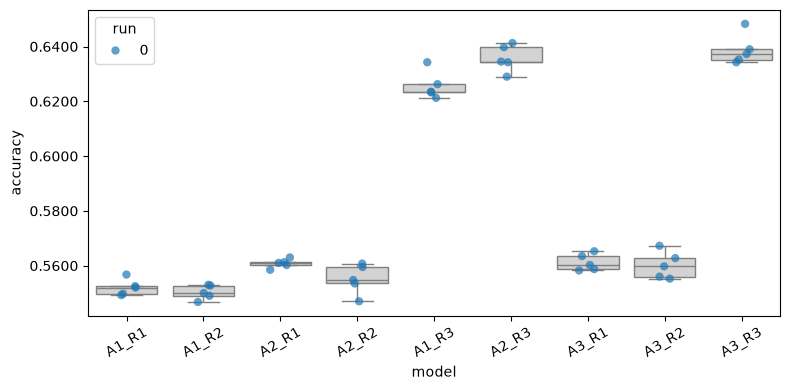

,R1,R2,R3
A1,0.5520,0.5503,0.6257
A2,0.5608,0.5551,0.6358
A3,0.5612,0.5602,0.6388


In [16]:
df_results = part1.analysis.make_data_frame(my_classifiers)
part1.analysis.plot_box_and_points(df_results)

# table: mean accuracy for every architecture (rows) and representation (columns)
table = pd.DataFrame(index=["A1", "A2", "A3"], columns=["R1", "R2", "R3"], dtype=float)
for a in ["A1", "A2", "A3"]:
    for r in ["R1", "R2", "R3"]:
        name = a + "_" + r
        table.loc[a, r] = df_results[df_results["model"] == name]["accuracy"].mean()
table.round(4)

**ROPE (region of practical equivalence).** An accuracy measured on n examples has a standard error of about √(acc·(1−acc)/n). On the ~10k test pairs that is about 0.005, so a difference smaller than about 2 standard errors (**0.01**) is within the noise of the measurement itself. We call such differences *practically equivalent*. For comparison we also report the tutorial's ROPE of 0.005.

In [17]:
acc = df_results["accuracy"].mean()
n = len(test_pairs)
standard_error = np.sqrt(acc * (1 - acc) / n)
print("standard error on the test set (n =", n, "):", round(standard_error, 4))

ROPE = 0.01

standard error on the test set (n = 9824 ): 0.005


**Comparisons, one factor at a time.** For each pair of systems A and B, `BenavoliCorrelatedT` gives a distribution over the mean accuracy difference (B − A), taking into account that cross-validation folds overlap. We report the probability that A is better, that they are practically equivalent (difference inside the ROPE), and that B is better.

1. **Representations** (architecture fixed to A1): R1 vs R2, R2 vs R3
2. **Architectures** (representation fixed to the best one from step 1): A1 vs A2, A2 vs A3
3. **Best system vs. the tutorial default** (A1_R1)

best representation with A1: R3 | best system overall: A3_R3


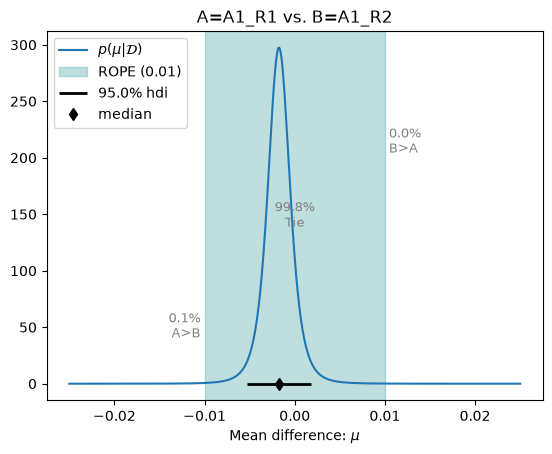

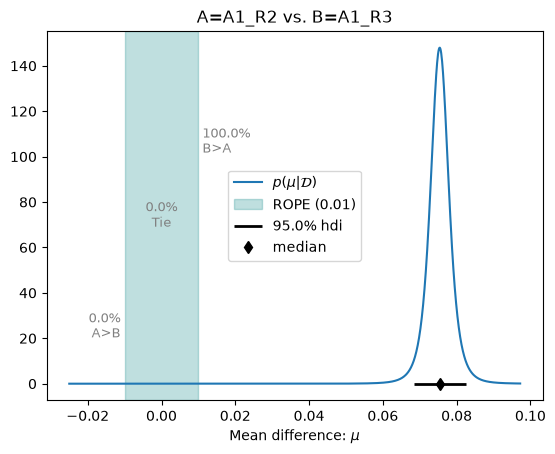

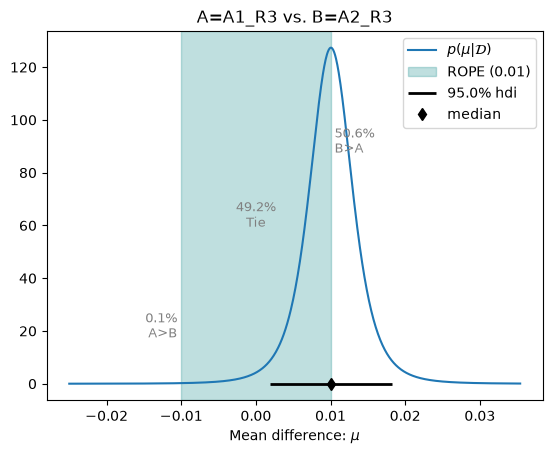

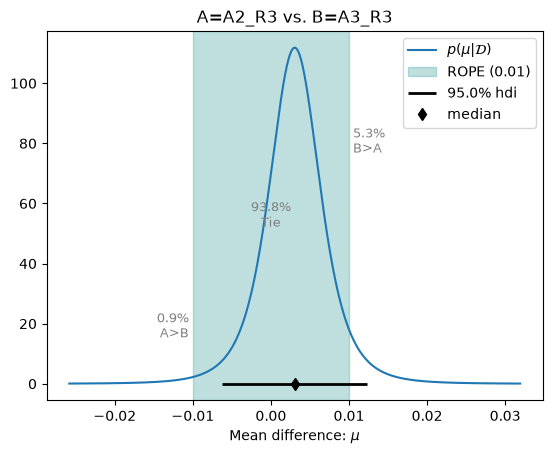

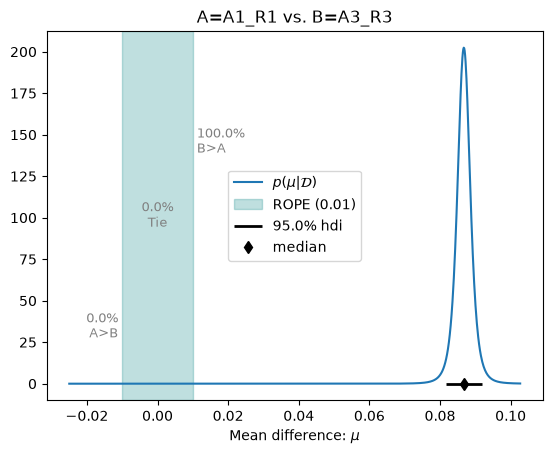

,A,B,mean diff (B-A),effect size,P(A better) 0.005,P(equivalent) 0.005,P(B better) 0.005,P(A better) 0.01,P(equivalent) 0.01,P(B better) 0.01
0,A1_R1,A1_R2,-0.002,-1.388,0.031,0.966,0.003,0.001,0.998,0.000
1,A1_R2,A1_R3,0.075,29.756,0.000,0.000,1.000,0.000,0.000,1.000
2,A1_R3,A2_R3,0.010,3.414,0.003,0.077,0.919,0.001,0.492,0.506
3,A2_R3,A3_R3,0.003,0.910,0.037,0.667,0.296,0.009,0.938,0.053
4,A1_R1,A3_R3,0.087,46.832,0.000,0.000,1.000,0.000,0.000,1.000


In [18]:
def get_accuracies(name):
    # all fold accuracies of one system, as one array
    accuracies = []
    for result in my_classifiers[name]:
        for accuracy in result["accuracies"].values():
            accuracies.append(accuracy)
    return np.array(accuracies)


def compare(a, b):
    acc_a = get_accuracies(a)
    acc_b = get_accuracies(b)

    # if the accuracies are exactly the same on every fold there is nothing to compare
    if np.allclose(acc_a, acc_b):
        print(a, "and", b, "have identical accuracies on every fold -> practically equivalent")
        return {"A": a, "B": b, "mean diff (B-A)": 0.0}

    posterior = part1.analysis.BenavoliCorrelatedT(acc_a, acc_b, runs=len(my_seeds), names=[a, b])
    row = {"A": a, "B": b, "mean diff (B-A)": posterior.mean_diff, "effect size": posterior.effect_size}

    for rope in [0.005, ROPE]:
        p_a, p_tie, p_b = posterior.probs(rope)
        row["P(A better) " + str(rope)] = p_a
        row["P(equivalent) " + str(rope)] = p_tie
        row["P(B better) " + str(rope)] = p_b

    posterior.plot(ROPE)
    plt.show()
    return row


# best representation when the architecture is A1
best_rep = "R1"
for r in ["R2", "R3"]:
    if get_accuracies("A1_" + r).mean() > get_accuracies("A1_" + best_rep).mean():
        best_rep = r

# best system overall
best_system = None
for name in my_classifiers:
    if best_system is None or get_accuracies(name).mean() > get_accuracies(best_system).mean():
        best_system = name

print("best representation with A1:", best_rep, "| best system overall:", best_system)

pairs_to_compare = [
    ("A1_R1", "A1_R2"),
    ("A1_R2", "A1_R3"),
    ("A1_" + best_rep, "A2_" + best_rep),
    ("A2_" + best_rep, "A3_" + best_rep),
]
if best_system != "A1_R1":
    pairs_to_compare.append(("A1_R1", best_system))

rows = []
for a, b in pairs_to_compare:
    rows.append(compare(a, b))
comparison = pd.DataFrame(rows)
comparison.round(3)

## 8. Test set (once)

Finally we train the best system on all 20,000 training pairs and evaluate it **once** on SNLI's test set. We report accuracy, macro-F1 and the confusion matrix, which shows which labels get confused with each other.

Transforming documents...
Document transformation done! Time taken: 1.230 seconds
Dataloader done! Time taken: 0.419 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0923 | train acc: 0.3651 | val loss: 1.0750 | val acc: 0.4745
Epoch 02 | train loss: 1.0579 | train acc: 0.4738 | val loss: 1.0295 | val acc: 0.5655
Epoch 03 | train loss: 1.0135 | train acc: 0.5333 | val loss: 0.9789 | val acc: 0.5920
Epoch 04 | train loss: 0.9700 | train acc: 0.5635 | val loss: 0.9390 | val acc: 0.6095
Epoch 05 | train loss: 0.9376 | train acc: 0.5820 | val loss: 0.9058 | val acc: 0.6215
Epoch 06 | train loss: 0.9115 | train acc: 0.6000 | val loss: 0.8803 | val acc: 0.6325
Epoch 07 | train loss: 0.8839 | train acc: 0.6174 | val loss: 0.8590 | val acc: 0.6425
Epoch 08 | train loss: 0.8622 | train acc: 0.6242 | val loss: 0.8426 | val acc: 0.6495
Epoch 09 | train loss: 0.8414 | train acc: 0.6395 | val loss: 0.8282 | val acc: 0.6605
Epoch 10 | train loss: 0.8252 | train acc: 0.6470 | val loss: 0.8164 | val acc: 0.6605
Epoch 11 | train loss: 0.8081 | train acc: 0.6586 | val loss: 0.8070 | val acc: 0.6655
Epoch 12 | train loss: 0.7990 | train acc: 

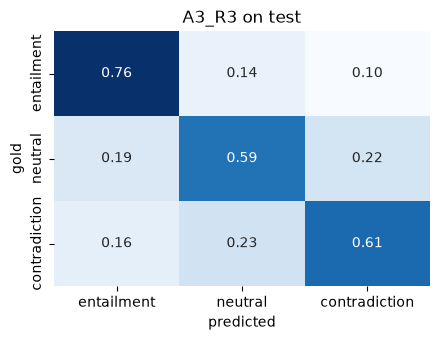

In [19]:
final = best_system
architecture_name = final.split("_")[0]
representation_name = final.split("_")[1]

if representation_name == "R1":
    encoder = R1
elif representation_name == "R2":
    encoder = R2
else:
    encoder = R3

if architecture_name == "A1":
    architecture = A1
elif architecture_name == "A2":
    architecture = A2
else:
    architecture = A3

test_texts = []
gold = []
for pair, label in test_pairs:
    test_texts.append(pair)
    gold.append(label)

if architecture["model_option"] == "logistic":
    model = part1.loglin.fit(train_pairs, encoder, max_iter=architecture["loglin_args"]["max_iter"])
    preds = part1.loglin.predict(test_texts, model, encoder)
else:
    # val_pairs is only used to pick the best epoch, the test set is only used for predicting
    settings = architecture["smlp_args"]
    part1.smlp.train_neural_network_model(
        train_pairs, val_pairs, len(LABELS), encoder, save_to="results/final_model",
        hidden_dim=settings["hidden_dim"], dropout=settings["dropout"], batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        num_epochs=settings["num_epochs"],
    )
    model = part1.smlp.load("results/final_model")
    probabilities = part1.smlp.predict_probs(test_texts, model, encoder, batch_size=256)
    preds = probabilities.argmax(axis=1)   # the label with the highest probability

print(final, "on the test set: accuracy", round(accuracy_score(gold, preds), 4),
      "| macro-F1", round(f1_score(gold, preds, average="macro"), 4))
print(classification_report(gold, preds, target_names=list(LABELS)))

cm = confusion_matrix(gold, preds, normalize="true")
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=list(LABELS), yticklabels=list(LABELS))
plt.xlabel("predicted")
plt.ylabel("gold")
plt.title(final + " on test")
plt.tight_layout()
plt.show()

## Conclusions

**Data**
- The labels are balanced (contradiction 34.0%, neutral 33.2%, entailment 32.9%), so **accuracy is a fair metric**. The majority baseline is **0.340**.
- Premises have the same length for every label (~12.9 words), but hypotheses differ: entailment is shortest (6.7 words), neutral longest (8.2 words). Negation occurs about 6× more often in contradiction hypotheses (4.9%) than in the others (<1%), but is rare overall.

**Tokenizer**
- With a vocabulary of 1,000, frequent words stay whole (`▁man`, `▁holding`) but rarer words are split into many small pieces (`introduces` → `▁in t ro d u c es`). A larger vocabulary might give more informative tokens.

**Representations** (all comparisons with ROPE = 0.01)
- **R1 vs R2:** 0.552 vs 0.550, P(equivalent) = 0.998 → **practically equivalent**. This is expected: in short sentences almost every token occurs only once, so counts (R2) and indicators (R1) are nearly the same vector.
- **R2 vs R3:** 0.550 → 0.626 (+0.075), P(R3 better) = 1.00 → **by far the largest effect in the project**. Features that describe the relation between premise and hypothesis help a lot.
- The gain from R3 is about the same for all three architectures (A1 +0.075, A2 +0.080, A3 +0.080). So the MLPs do **not** learn these relations by themselves from R1/R2; they need them as explicit features.

**Architectures** (on R3)
- **A1 vs A2:** 0.626 → 0.637 (+0.012), P(A2 better) = 0.74, P(equivalent) = 0.26 → the MLP is **probably slightly better**, but the difference is close to the ROPE.
- **A2 vs A3:** 0.637 → 0.640 (+0.002), P(equivalent) = 0.997 → **practically equivalent**. A2 overfits (train 0.656 vs validation 0.577 at epoch 10, gap +0.079), but the extra regularisation in A3 only reduced the gap a little (+0.070) and did not improve accuracy.
- With R1 and R2, the MLPs are only marginally better than the log-linear model (+0.005 to +0.009).

**Best system**
- **A3_R3**: CV accuracy **0.640**, test accuracy **0.654**, macro-F1 **0.650**. Compared to the tutorial default A1_R1 (0.552): +0.088, P(better) = 1.00.
- A2_R3 and A3_R3 are practically equivalent, and A1_R3 is close. In practice, **A1_R3 could be a sensible choice** too: it trains in seconds instead of minutes and its weights can be inspected.
- The test accuracy is a bit higher than the CV accuracy, probably because the final model is trained on all 20k pairs instead of 16k per fold.

**Confusion matrix**
- **Entailment** is recognised best (recall 0.76). **Neutral** is the hardest (recall 0.57): it is confused with both entailment (20%) and contradiction (23%). Contradiction is often predicted as neutral (21%).
- This makes sense: *neutral* means the hypothesis adds information that is not in the premise, and with bag-of-words features (no word order, no meaning) that is hard to detect.

**Limitations**
- Only 20k of ~550k training pairs, one random sample and one seed (5 measurements per system).
- Bag-of-words ignores word order ("man bites dog" = "dog bites man").
- The folds are split randomly by pair, so the same premise can appear in training and validation.
- For the MLPs, the course code reports each fold's accuracy at the epoch with the best loss on that same fold, which slightly favours the MLPs.
- The best system was chosen on the CV results; A3 was designed after looking at A2 on a separate validation set.